## Greenery Data Exploration

Layers explored & built:
1. DBSN `ar_vrd`   → parks / gardens (types `01`, `95`)
2. DBSN `pe_unis`  → uniform open spaces (parks, gardens, playgrounds)
3. OSM             → `leisure=park` / `garden`
4. Municipality data source

Output: `{city}_greenery.gpkg` with layers `osm_public` and/or `municipality` and/or `dsbn`.
This file is the input for `300_walkability_isochrone_computation.ipynb`.

In [4]:
!pip install duckdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━ 12.6/16.0 MB 8.9 MB/s eta 0:00:01
Resuming download duckdb-1.5.1-cp312-cp312-macosx_10_13_x86_64.whl (12.6 MB/16.0 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 3.9 MB/s  0:00:00 eta 0:00:01


In [ ]:
import os
os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

In [ ]:
import sys
import duckdb
import geopandas as gpd
from shapely import wkb
from config import DB_PATH, get_city_cfg, CRS_WGS, CRS_METRIC
import duckdb, geopandas as gpd, shapely.wkb
from config import DB_PATH, get_city_cfg
import warnings
warnings.filterwarnings("ignore")
from shapely.strtree import STRtree

import shapely
import fiona
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import osmnx as ox
import pandas as pd

In [6]:
print(os.getcwd())
print(os.listdir('.'))

/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index
['.nord-ovest-latest.osm.pbf.icloud', 'notes_db.txt', '.DS_Store', 'config.py', 'fig', 'cache', 'LICENSE', 'requirements.txt', 'images', 'load_data_db.py', 'code', '__pycache__', 'docs', 'README.md', 'results', 'logs', '.gitignore', '3_30_300.duckdb', 'db', '.git', '.vscode', 'data', 'create_db.py', 'data_exploration']


In [7]:

# Initialize
CITY = "milano"
cfg = get_city_cfg(CITY)
src = cfg["data_sources"]

# Connect to DuckDB (if you still need it later)
con = duckdb.connect(str(DB_PATH))
con.execute("LOAD spatial;")

In [8]:
def clip_and_reset(gdf, boundary):
    """Clip to boundary and reset index"""
    clipped = gpd.clip(gdf, boundary)
    return clipped.reset_index(drop=True)

def area_ha(gdf):
    """Add area column in hectares"""
    gdf = gdf.copy()
    gdf["area_ha"] = gdf.geometry.area / 1e4
    return gdf

def describe_areas(gdf, title=""):
    """Print area statistics"""
    if gdf.empty:
        print(f"  {title}: No features")
        return
    total = gdf["area_ha"].sum()
    print(f"  {title}: {total:.0f} ha ({len(gdf)} features)")

## boundary

In [9]:
boundary = gpd.read_file(src["boundary"]).to_crs(CRS_METRIC)
boundary_ha = boundary.geometry.area.sum() / 1e4
boundary_wgs84 = boundary.to_crs(CRS_WGS).geometry.union_all()
print(f"Boundary: {boundary_ha:.0f} ha")


Boundary: 18176 ha


In [10]:
muni_raw     = None
dsbn_pe_unis = None
dsbn_ar_vrd  = None

## 1. DBSN ar_vrd (area verde)
Only runs if a DBSN geodatabase is available for this city. Skip otherwise.

In [11]:

if "area_verde" in cfg["park_layers"]:
    path = cfg["park_layers"]["area_verde"]
    if os.path.exists(path):
        ar_vrd = gpd.read_file(path).to_crs(CRS_METRIC)
        print(f"area_verde: Total features: {len(ar_vrd):,}")
        if "ar_vrd_ty" in ar_vrd.columns:
            print(ar_vrd["ar_vrd_ty"].value_counts().to_string())
        
        dsbn_ar_vrd = (
            ar_vrd
            .query('ar_vrd_ty in ["01", "95"]')
            .pipe(clip_and_reset, boundary)
            .pipe(area_ha)
        )
        print("area_verde parks+gardens (types 01,95):")
        describe_areas(dsbn_ar_vrd)
    else:
        print(f"area_verde file not found: {path}")
        dsbn_ar_vrd = None
else:
    print("area_verde: Not configured for this city")
    dsbn_ar_vrd = None


area_verde: Not configured for this city


## 2. DBSN - pe_unis (settlement units)
Types: 11=park/garden, 1001=playground, 1101=garden, 1103=park

In [12]:
if "pe_unis" in cfg["park_layers"]:
    path = cfg["park_layers"]["pe_unis"]
    if os.path.exists(path):
        pe_unis = gpd.read_file(path).to_crs(CRS_METRIC)
        print(f"pe_unis: Total features: {len(pe_unis):,}")

        GREEN_TYPES = ["11", "1001", "1101", "1102", "1103"]
        dsbn_pe_unis = (
            pe_unis
            .pipe(clip_and_reset, boundary)
            .pipe(area_ha)
            .loc[lambda df: df["pe_uins_ty"].isin(GREEN_TYPES)]
        )
        print("pe_unis green types:")
        describe_areas(dsbn_pe_unis)
    else:
        print(f"pe_unis file not found: {path}")
        dsbn_pe_unis = None
else:
    print("pe_unis: Not configured for this city")
    dsbn_pe_unis = None


pe_unis: Not configured for this city


## 3. OSM leisure = park / garden

In [13]:
PRIVATE_ACCESS = {"private", "no", "restricted", "permit", "customers"}

osm_raw = (
    ox.features_from_polygon(boundary_wgs84, tags={"leisure": ["park", "garden"]})
    .to_crs(CRS_METRIC)
    .pipe(clip_and_reset, boundary)
    .pipe(area_ha)
)
osm_raw = osm_raw[osm_raw.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

osm_public = osm_raw.loc[
    osm_raw["access"].isna() | ~osm_raw["access"].isin(PRIVATE_ACCESS)
].copy()

print(f"OSM parks+gardens — all: {len(osm_raw)}")
print(f"OSM parks+gardens — public:")
describe_areas(osm_public)

OSM parks+gardens — all: 1687
OSM parks+gardens — public:
  : 2001 ha (1556 features)


## 4. Municipality data source
Only runs if the city config has a `parks_municipal` or `parks_dsnb` key pointing to a local file.

In [14]:

if "municipal" in cfg["park_layers"]:
    path = cfg["park_layers"]["municipal"]
    if os.path.exists(path):
        muni_raw = (
            gpd.read_file(path)
            .to_crs(CRS_METRIC)
            .pipe(clip_and_reset, boundary)
            .pipe(area_ha)
        )
        print("Municipality parks:")
        describe_areas(muni_raw)
    else:
        print(f"Municipal parks file not found: {path}")
        muni_raw = None
else:
    print("Municipal parks: Not configured for this city")
    muni_raw = None


Municipality parks:
  : 774 ha (1065 features)


## 5. Summary comparison

## 6. Source choice visualisation
Visual comparison to inform which layers to save for the isochrone pipeline.

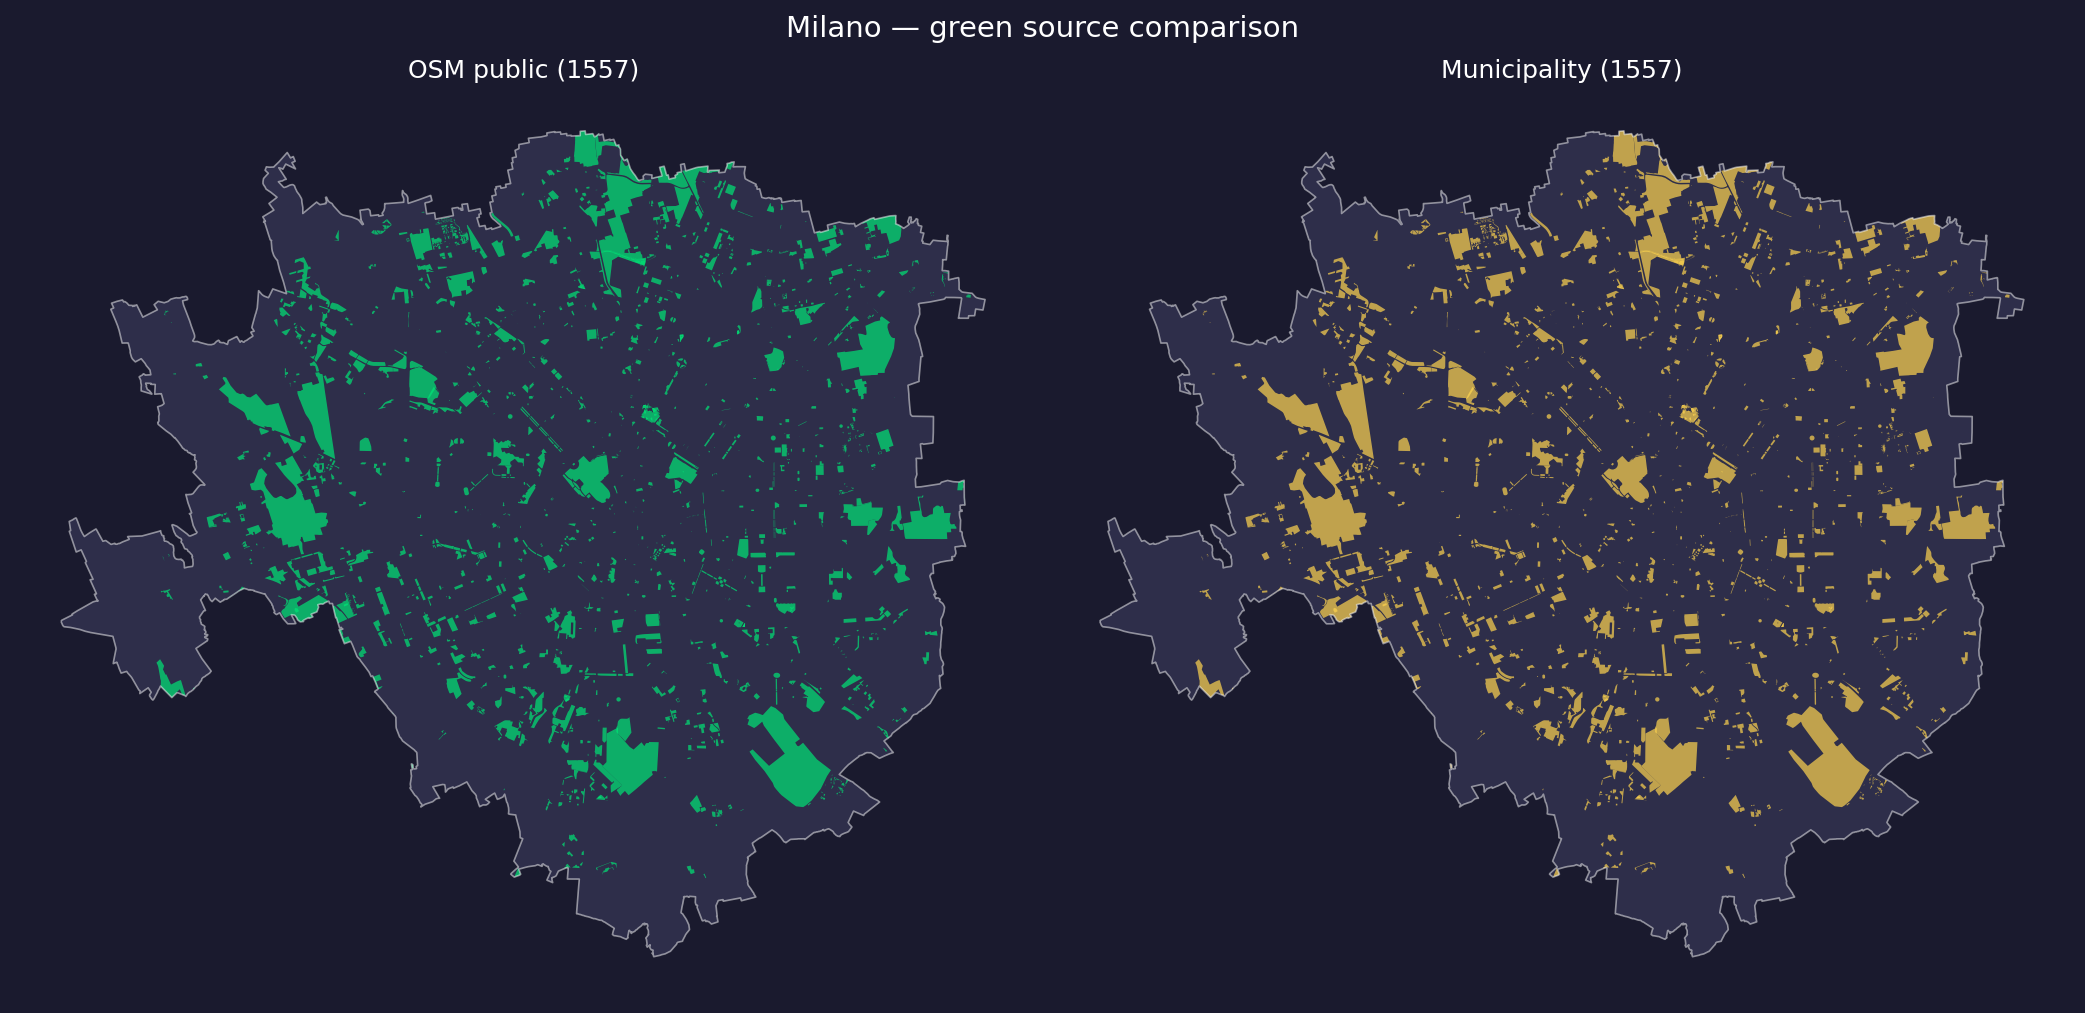

In [ ]:
C_OSM   = "#00e676"
C_MUNI  = "#FFD54F"
C_SETT  = "#c44dff"
FIG_BG  = "#1a1a2e"
PAN_BG  = "#12122a"
LAND_BG = "#2e2e4a"

n_panels = 1 + (muni_raw is not None) + (pe_green is not None)
fig, axes = plt.subplots(1, n_panels, figsize=(7 * n_panels, 7), dpi=150)
if n_panels == 1:
    axes = [axes]
fig.patch.set_facecolor(FIG_BG)
for ax in axes:
    ax.set_facecolor(PAN_BG)
    boundary.plot(ax=ax, color=LAND_BG, zorder=0)
    boundary.boundary.plot(ax=ax, color="white", linewidth=0.8, alpha=0.5, zorder=5)
    ax.axis("off")

idx = 0
osm_public.plot(ax=axes[idx], color=C_OSM, alpha=0.7, zorder=3)
axes[idx].set_title(f"OSM public ({len(osm_public)})", color="white", fontsize=12)
idx += 1

if muni_raw is not None:
    muni_raw.plot(ax=axes[idx], color=C_MUNI, alpha=0.7, zorder=3)
    axes[idx].set_title(f"Municipality ({len(muni_raw)})", color="white", fontsize=12)
    idx += 1

if dsbn_ar_vrd is not None:
    dsbn_ar_vrd.plot(ax=axes[idx], color=C_SETT, alpha=0.7, zorder=3)
    axes[idx].set_title(f"DBSN pe_unis ({len(dsbn_ar_vrd)})", color="white", fontsize=12)

if dsbn_pe_unis is not None:
    dsbn_pe_unis.plot(ax=axes[idx], color=C_SETT, alpha=0.7, zorder=3)
    axes[idx].set_title(f"DBSN pe_unis ({len(dsbn_pe_unis)})", color="white", fontsize=12)

fig.suptitle(f"{CITY.title()} — green source comparison", color="white", fontsize=14)
plt.tight_layout()
plt.show()

## 7. Save: edit layers_to_save based on visual inspection above

In [17]:
def prep_save(gdf, source, layer_type):
    cols = ["geometry", "area_ha"]
    for c in ["nome", "name", "descrizione", "NOME", "NAME"]:
        if c in gdf.columns:
            cols.append(c)
            break
    return gdf[cols].assign(source=source, layer_type=layer_type).copy()

In [18]:

layers_to_save = {
    "osm_public": prep_save(osm_public, "OSM", "osm_public"),
}
if muni_raw is not None:
    layers_to_save["municipality"] = prep_save(muni_raw, "MUNICIPALITY", "municipality")
if dsbn_pe_unis is not None:
     layers_to_save["pe_unis"] = prep_save(dsbn_pe_unis, "DBSN", "pe_unis")
if dsbn_ar_vrd is not None:
     layers_to_save["ar_vrd"] = prep_save(dsbn_ar_vrd, "DBSN", "pe_unis")
     


In [26]:
def deduplicate_parks(parks: gpd.GeoDataFrame, overlap_threshold: float = 0.7) -> gpd.GeoDataFrame:
    """
    Remove OSM polygons substantially covered by any non-OSM (authoritative) polygon.
    Logic: if an OSM park's overlap with any municipality/DBSN polygon exceeds
    overlap_threshold of its own area, drop it.
    """
    authoritative = parks[parks["layer_type"] != "osm_public"].copy().reset_index(drop=True)
    osm = parks[parks["layer_type"] == "osm_public"].copy()

    if authoritative.empty or osm.empty:
        return parks

    auth_tree = STRtree(authoritative.geometry.values)

    drop_idx = []
    for idx, row in osm.iterrows():
        candidates = auth_tree.query(row.geometry, predicate="intersects")
        if len(candidates) == 0:
            continue
        overlap = sum(
            row.geometry.intersection(authoritative.geometry.iloc[c]).area
            for c in candidates
        )
        if overlap / row.geometry.area >= overlap_threshold:
            drop_idx.append(idx)

    print(f"Dropping {len(drop_idx)} OSM parks covered by authoritative polygons")
    return parks.drop(index=drop_idx).reset_index(drop=True)

In [ ]:
# combine all layers into one
# layer_type column 
all_layers = pd.concat(layers_to_save.values(), ignore_index=True)
greenery = deduplicate_parks(all_layers)   # drops OSM covered by municipal
greenery["park_id"] = range(len(greenery))


Dropping 86 OSM parks covered by authoritative polygons


: 

## write merged+deduplicated result to DuckDB preprocessing


DuckDB can't directly ingest GeoPandas geometry columns via register(). = need to convert the geometry to WKB (binary) first, then cast it back to DuckDB's spatial type with ST_GeomFromWKB.

In [25]:
def gdf_to_duckdb(con, gdf: gpd.GeoDataFrame, schema_table: str, city: str):
    """Write a GeoDataFrame to DuckDB spatial table via WKB serialization."""
    df = gdf.copy()
    df["geom_wkb"] = df.geometry.apply(lambda g: g.wkb if g is not None else None)
    df = df.drop(columns="geometry")
    
    con.register("_tmp", df)
    con.execute(f"""
        CREATE OR REPLACE TABLE {schema_table} AS
        SELECT '{city}' AS city,
               * EXCLUDE geom_wkb,
               ST_GeomFromWKB(geom_wkb) AS geometry
        FROM _tmp;
    """)
    con.unregister("_tmp")

con = duckdb.connect(str(DB_PATH))
con.execute("LOAD spatial;")
con.execute("CREATE SCHEMA IF NOT EXISTS preprocessing;")

#1. individual source layers 
for layer_type, gdf in layers_to_save.items():
    table = f"preprocessing.{CITY}_parks_{layer_type}"
    gdf_to_duckdb(con, gdf, table, CITY)
    print(f"  {table}: {len(gdf):,} features")

#2. merged + deduplicated greenery 
gdf_to_duckdb(con, greenery, f"preprocessing.{CITY}_parks_greenery", CITY)
print(f"  preprocessing.{CITY}_parks_greenery: {len(greenery):,} features (deduplicated)")
print(greenery["layer_type"].value_counts().to_string())

con.close()

  preprocessing.milano_parks_osm_public: 1,556 features
  preprocessing.milano_parks_municipality: 1,065 features
  preprocessing.milano_parks_greenery: 2,535 features (deduplicated)
layer_type
osm_public      1470
municipality    1065


In [ ]:
#optional: export back from DuckDB to GeoPackage 
# df = con.execute(f"""
#     SELECT * EXCLUDE geometry,
#            ST_AsWKB(geometry) AS geom_wkb
#     FROM preprocessing.{CITY}_parks_greenery
# """).df()
# gdf = gpd.GeoDataFrame(
#     df.drop(columns="geom_wkb"),
#     geometry=df["geom_wkb"].apply(lambda b: shapely.wkb.loads(bytes(b))),
#     crs=CRS_WGS
# )
# out_path = src["parks_gardens"]   # or any other path
# gdf.to_file(out_path, layer="greenery", driver="GPKG")
# print(f"saved {len(gdf):,} features → {out_path}")